**Практическая работа №6**

In [20]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("titanic.csv")
print(df.head())

features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print(X.isnull().sum())
print(X.dtypes)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Pc

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер X_train:", X_train.shape)  # (712, 6) ≈ 80%
print("Размер X_test:", X_test.shape)    # (179, 6) ≈ 20%

Размер X_train: (712, 6)
Размер X_test: (179, 6)


**Ответы на вопросы:**

Тестовая выборка нужна, чтобы оценить модель на данных, которые она не видела при обучении. Иначе оценка будет завышенной — модель просто «запомнит» ответы.

fit_transform() только для train: параметры масштабирования (среднее, std) вычисляются только по обучающим данным, чтобы не «подглядывать» в тест. К тесту применяем уже обученный scaler через transform().

In [22]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:", y_test.iloc[:10].to_list())

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


Совпали позиции 0, 1, 3, 4, 6, 7, 8, 9. Ошибки: позиция 2 (предсказано 0, реально 1) и позиция 5 (предсказано 0, реально 1). 0 — пассажир не выжил, 1 — выжил.

In [23]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.8044692737430168
Precision: 0.765625
Recall: 0.7101449275362319
F1: 0.7368421052631579
Confusion matrix:
 [[95 15]
 [20 49]]

               precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



**Ответы:**

Доля правильных предсказаний — Accuracy.

Насколько модель находит реально выживших — Recall (полнота).

FP (ложноположительные): модель сказала «выжил», а на самом деле погиб. FN (ложноотрицательные): модель сказала «погиб», а на самом деле выжил.

In [24]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", accuracy_score(y_test, y_pred_tree))
print("Precision дерева:", precision_score(y_test, y_pred_tree))
print("Recall дерева:", recall_score(y_test, y_pred_tree))
print("F1 дерева:", f1_score(y_test, y_pred_tree))
print("Confusion matrix дерева:\n", confusion_matrix(y_test, y_pred_tree))

Accuracy дерева: 0.7821229050279329
Precision дерева: 0.875
Recall дерева: 0.5072463768115942
F1 дерева: 0.6422018348623854
Confusion matrix дерева:
 [[105   5]
 [ 34  35]]


Логистическая регрессия: Accuracy 0.804, Precision 0.766, Recall 0.710, F1 0.737. Дерево решений: Accuracy 0.782, Precision 0.875, Recall 0.507, F1 0.642. Логистическая регрессия лучше по Accuracy, Recall и F1 — она находит больше реально выживших (recall 0.71 против 0.51). Дерево точнее в положительных предсказаниях (precision 0.875), но пропускает много выживших (FN: 34 против 20). Для задачи выживаемости важнее Recall, поэтому логистическая регрессия предпочтительнее.

In [25]:
corr = df[["Survived", "Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()
corr["Sex"] = corr["Sex"].map({"male": 0, "female": 1})

corr_matrix = corr.corr()
print(corr_matrix["Survived"].sort_values(ascending=False))

Survived    1.000000
Sex         0.543351
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Name: Survived, dtype: float64


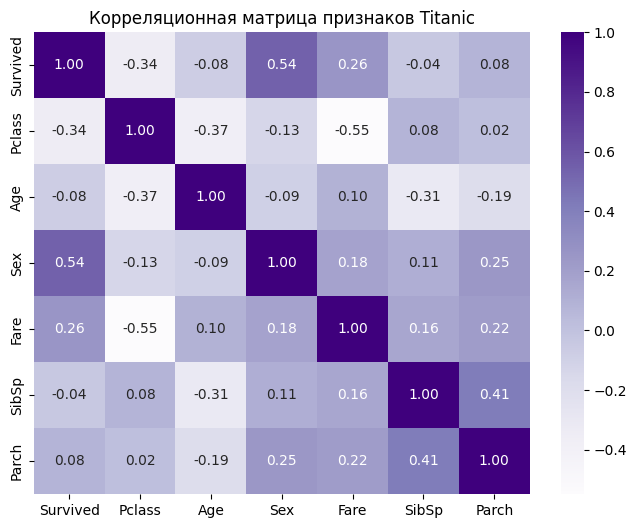

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Purples")
plt.title("Корреляционная матрица признаков Titanic")
plt.show()

Вывод: данные подготовлены (пропуски Age заполнены медианой, Sex закодирован), выполнено разделение 80/20 со стратификацией. Корреляционный анализ: сильнейшая положительная связь с Survived у пола (Sex, 0.54), сильнейшая отрицательная — у класса (Pclass, −0.34). Логистическая регрессия предсказывает выживаемость с accuracy ≈ 0.80, дерево решений — ≈ 0.78. Модель предсказывает удовлетворительно, но recall по выжившим (0.71) означает, что примерно треть реально выживших она пропускает. Качество можно улучшить добавлением признаков (Embarked, Cabin, размер семьи) и подбором гиперпараметров.